# 01. Разведочный анализ исходных данных

**Цель ноутбука.** Сформировать воспроизводимое представление о датасете `raw_data/`: какие workload и сценарии присутствуют, как покрыты две модальности, насколько логи и KPI пригодны для синхронизации во времени, какие ограничения создают риск методологической ошибки.

В этом ноутбуке не строится модель. Его задача — обосновать последующие инженерные решения: строгую временную постановку, разбиение по workload/run, использование `gap10`, сохранение масок доступности модальностей и переход от классификации отдельных окон к слою раннего предупреждения.

**Основной тезис.** В данной задаче факт сбоя и полезное раннее предупреждение не совпадают. Система должна оценивать состояние до события, поэтому анализ данных должен быть сосредоточен на времени, доступности модальностей и признаках потенциальной утечки.


In [1]:
from pathlib import Path
import json
import random
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from dashboard.final_data_pipeline import (
    PROJECT_ROOT,
    SEED,
    KEYWORDS,
    KPI_SELECTED_COLUMNS,
    parse_raw_log_file,
    scan_raw_data,
    write_json,
    _read_kpi_file,
)

random.seed(SEED)
np.random.seed(SEED)

RAW_DATA = PROJECT_ROOT / "raw_data"
ARTIFACT_DIR = PROJECT_ROOT / "dashboard" / "artifacts"
REPORT_DIR = ARTIFACT_DIR / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

print(f"Источник данных: {RAW_DATA}")
print(f"Каталог артефактов: {ARTIFACT_DIR}")


Источник данных: C:\Main\DGTU\ВКР\Diploma\raw_data
Каталог артефактов: C:\Main\DGTU\ВКР\Diploma\dashboard\artifacts


## 1. Инвентаризация источников

На первом шаге проверяется не содержимое признаков, а физическая структура датасета: какие сценарии имеют raw logs, какие имеют KPI и где присутствуют обе модальности одновременно. Это важно для честной мультимодальной постановки: модель не должна незаметно обучаться только на одной модальности, если вторая отсутствует или плохо синхронизирована.


,статус пары,тип сценария,запуски,workload
0,KPI_ONLY,normal,7,1
1,LOG_ONLY,normal,2,2
2,MISSING,failure,5,5
3,STRICT,failure,352,16
4,STRICT,normal,88,15


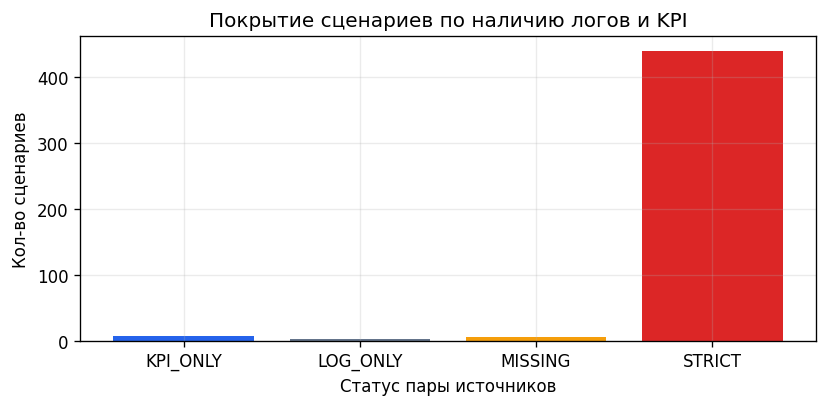

In [2]:
inventory, issues = scan_raw_data(RAW_DATA)
strict = inventory.loc[inventory["pair_status"].eq("STRICT")].copy()

coverage_summary = (
    inventory.groupby(["pair_status", "scenario_type"], dropna=False)
    .agg(запуски=("run_id", "nunique"), workload=("workload", "nunique"))
    .reset_index()
    .rename(columns={"pair_status": "статус пары", "scenario_type": "тип сценария"})
)
display(coverage_summary)

fig, ax = plt.subplots(figsize=(7, 3.5))
pair_counts = inventory["pair_status"].value_counts().sort_index()
ax.bar(pair_counts.index, pair_counts.values, color=["#2563eb", "#64748b", "#f59e0b", "#dc2626"][: len(pair_counts)])
ax.set_title("Покрытие сценариев по наличию логов и KPI")
ax.set_ylabel("Кол-во сценариев")
ax.set_xlabel("Статус пары источников")
plt.tight_layout()
plt.show()


**Что показано.** Сколько scenario-level запусков имеют обе модальности (`STRICT`) и сколько относятся к неполным случаям.  
**Что наблюдается.** Основной обучающий контур должен использовать только пары, где одновременно доступны raw log и KPI.  
**Локальный вывод.** Неполные случаи не следует смешивать с supervised training; они полезны как диагностический материал для будущего degraded-mode, но не как основа финальной оценки.


## 2. Баланс workload и сценариев отказа

Данные имеют повторяющуюся структуру: один и тот же workload встречается в нормальных и аварийных сценариях. Поэтому случайное разбиение по строкам недопустимо: модель может запомнить локальные особенности конкретного запуска. Для итоговой проверки нужен split, который учитывает `run_id` и workload.


scenario_type,workload,сбой,норма,всего
0,aggregation,22,7,29
3,graph_pagerank,22,7,29
4,join,22,7,29
15,wordcount,22,7,29
11,sort,22,7,29
10,sleep,22,7,29
9,scan,22,7,29
8,rf,22,7,29
7,repartition,22,6,28
13,terasort,22,6,28


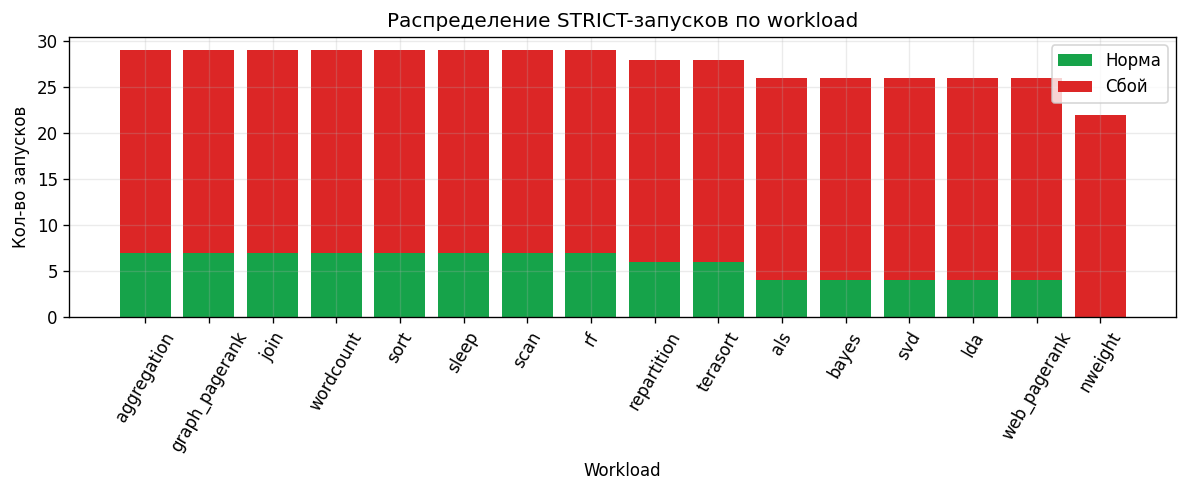

In [3]:
workload_summary = (
    strict.groupby(["workload", "scenario_type"])["run_id"]
    .nunique()
    .unstack(fill_value=0)
    .reset_index()
)
for col in ["normal", "failure"]:
    if col not in workload_summary.columns:
        workload_summary[col] = 0
workload_summary["всего"] = workload_summary["normal"] + workload_summary["failure"]
display(
    workload_summary.rename(columns={"workload": "workload", "normal": "норма", "failure": "сбой"})
    .sort_values("всего", ascending=False)
)

plot_data = workload_summary.sort_values("всего", ascending=False)
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.bar(plot_data["workload"], plot_data["normal"], label="Норма", color="#16a34a")
ax.bar(plot_data["workload"], plot_data["failure"], bottom=plot_data["normal"], label="Сбой", color="#dc2626")
ax.set_title("Распределение STRICT-запусков по workload")
ax.set_ylabel("Кол-во запусков")
ax.set_xlabel("Workload")
ax.tick_params(axis="x", rotation=60)
ax.legend()
plt.tight_layout()
plt.show()


**Что показано.** Баланс нормальных и аварийных сценариев в каждом workload.  
**Что наблюдается.** Workload является сильной группирующей переменной: разные сценарии внутри одного workload могут быть статистически ближе друг к другу, чем к другим workload.  
**Локальный вывод.** В дальнейшем split фиксируется на уровне workload/run-aware, а не на уровне отдельных окон.


## 3. Семейства отказов

Для раннего предупреждения важно, какие типы деградации представлены в данных. Одни семейства должны отражаться в логах, другие — в физических метриках системы. Если распределение семейств сильно неравномерно, глобальная метрика может быть завышена за счет нескольких простых сценариев.


,failure_family,запуски,workload
0,2nd_namenode_killed,16,16
1,2nd_namenode_suspended,16,16
2,cpu_stress,16,16
3,datanode_killed,16,16
4,datanode_suspended,16,16
5,io_stress,16,16
6,late_sub,16,16
7,lose_package,16,16
8,master_killed,16,16
9,master_suspended,16,16


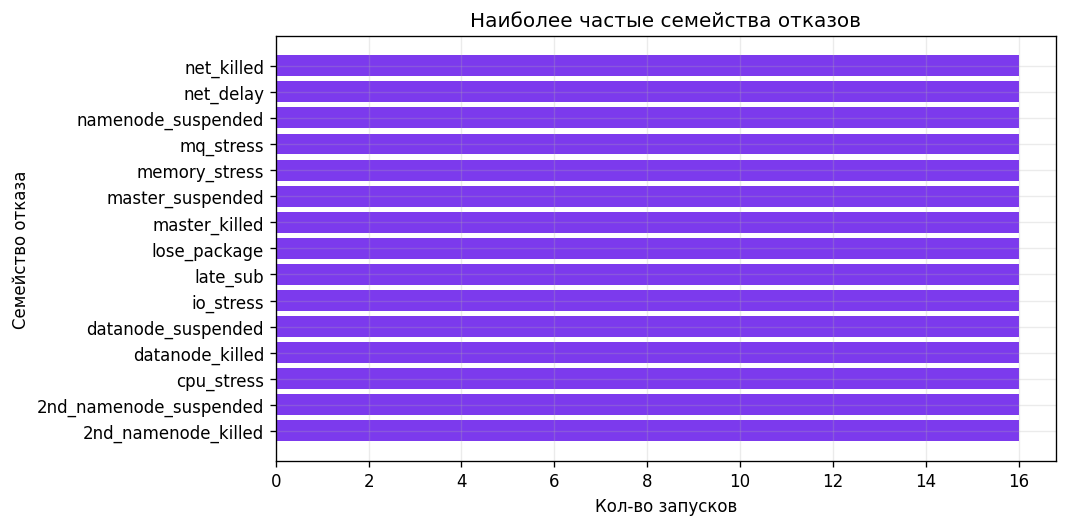

In [4]:
family_summary = (
    strict.loc[strict["scenario_type"].eq("failure")]
    .groupby("failure_family")
    .agg(запуски=("run_id", "nunique"), workload=("workload", "nunique"))
    .reset_index()
    .sort_values("запуски", ascending=False)
)
display(family_summary.head(20))

fig, ax = plt.subplots(figsize=(9, 4.5))
top_family = family_summary.head(15).sort_values("запуски")
ax.barh(top_family["failure_family"], top_family["запуски"], color="#7c3aed")
ax.set_title("Наиболее частые семейства отказов")
ax.set_xlabel("Кол-во запусков")
ax.set_ylabel("Семейство отказа")
plt.tight_layout()
plt.show()


**Локальный вывод.** ВКР нельзя защищать только на одном красивом сценарии. Итоговая система должна показывать глобальные метрики и несколько replay-кейсов разных типов: log-driven, KPI-driven, мультимодальный и нормальный.


## 4. Логовая модальность

Raw log относится к конкретному `scenario`, поэтому он является допустимым источником признаков. Но логовая модальность несет методический риск: поздние строки могут содержать уже наступивший симптом сбоя. Поэтому далее анализируется не только частота ошибок, но и длительность run, плотность логов и наличие явных warning/error-сигналов.


In [5]:
keyword_pattern = "|".join(re.escape(token) for token in KEYWORDS)
log_rows = []
for _, row in strict.iterrows():
    log_path = RAW_DATA / row["workload"] / "mapred_logs" / f"{row['scenario']}.log"
    events = parse_raw_log_file(log_path)
    if events.empty:
        continue
    levels = events["level"].astype(str)
    keyword_hits = events["message_norm"].astype(str).str.contains(keyword_pattern, regex=True, na=False)
    duration_sec = max((events["timestamp"].max() - events["timestamp"].min()).total_seconds(), 1.0)
    explicit_candidates = levels.isin(["WARN", "WARNING", "ERROR", "FATAL"]) | keyword_hits
    log_rows.append(
        {
            "run_id": row["run_id"],
            "workload": row["workload"],
            "scenario_type": row["scenario_type"],
            "failure_family": row["failure_family"],
            "duration_sec": duration_sec,
            "event_count": len(events),
            "events_per_sec": len(events) / duration_sec,
            "info_count": int(levels.eq("INFO").sum()),
            "warn_count": int(levels.isin(["WARN", "WARNING"]).sum()),
            "error_count": int(levels.isin(["ERROR", "FATAL"]).sum()),
            "keyword_count": int(keyword_hits.sum()),
            "explicit_anchor_available": int(explicit_candidates.any() and row["scenario_type"] == "failure"),
        }
    )

log_stats = pd.DataFrame(log_rows)
display(
    log_stats.groupby("scenario_type")
    .agg(
        запуски=("run_id", "nunique"),
        медиана_длительности_сек=("duration_sec", "median"),
        медиана_строк=("event_count", "median"),
        медиана_warn=("warn_count", "median"),
        медиана_error=("error_count", "median"),
        доля_explicit_anchor=("explicit_anchor_available", "mean"),
    )
    .reset_index()
)


,scenario_type,запуски,медиана_длительности_сек,медиана_строк,медиана_warn,медиана_error,доля_explicit_anchor
0,failure,348,75.5,332.5,0.0,0.0,0.402299
1,normal,88,66.5,327.0,0.0,0.0,0.000000


C:\Users\ipopi\AppData\Local\Temp\ipykernel_18076\120961046.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(box_data, labels=["Норма", "Сбой"], showfliers=False)


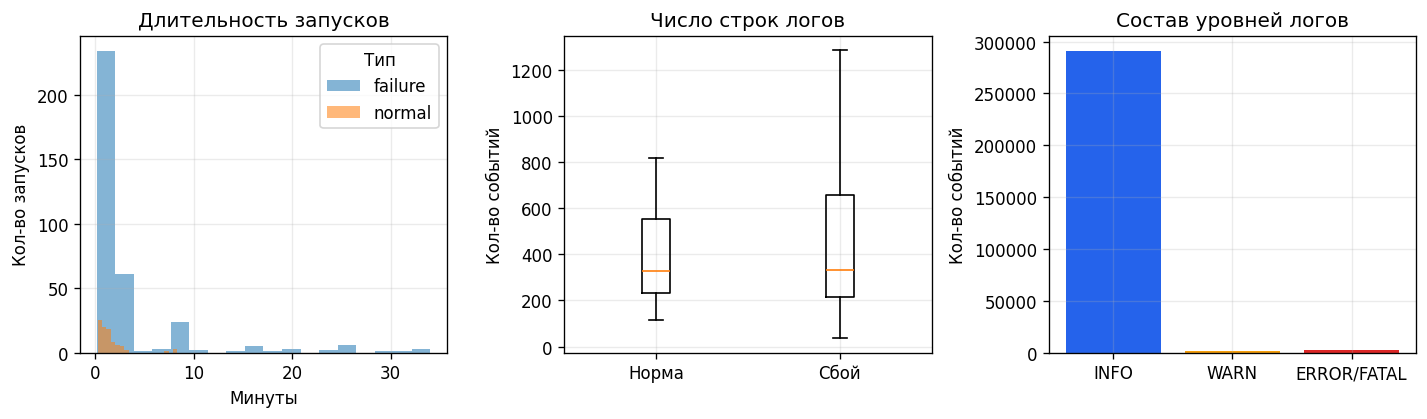

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))

for scenario_type, part in log_stats.groupby("scenario_type"):
    axes[0].hist(part["duration_sec"] / 60.0, bins=18, alpha=0.55, label=scenario_type)
axes[0].set_title("Длительность запусков")
axes[0].set_xlabel("Минуты")
axes[0].set_ylabel("Кол-во запусков")
axes[0].legend(title="Тип")

box_data = [log_stats.loc[log_stats["scenario_type"].eq(kind), "event_count"] for kind in ["normal", "failure"]]
axes[1].boxplot(box_data, labels=["Норма", "Сбой"], showfliers=False)
axes[1].set_title("Число строк логов")
axes[1].set_ylabel("Кол-во событий")

severity_totals = pd.Series(
    {
        "INFO": log_stats["info_count"].sum(),
        "WARN": log_stats["warn_count"].sum(),
        "ERROR/FATAL": log_stats["error_count"].sum(),
    }
)
axes[2].bar(severity_totals.index, severity_totals.values, color=["#2563eb", "#f59e0b", "#dc2626"])
axes[2].set_title("Состав уровней логов")
axes[2].set_ylabel("Кол-во событий")

plt.tight_layout()
plt.show()


**Что показано.** Временная длина запусков, объем логов и состав уровней логирования.  
**Что наблюдается.** Логи являются информативной модальностью, но warning/error-события могут находиться слишком близко к фактическому сбою.  
**Локальный вывод.** Логовые признаки должны строиться только из прошлого контекста окна, а проверка должна исключать слишком поздние окна через `gap10`.


## 5. KPI-модальность

KPI отражают физическое состояние системы: CPU, память, диск, сеть и системные очереди. В отличие от логов, KPI редко содержат явную текстовую причину сбоя, но они могут показывать деградацию ресурсов. Поэтому KPI полезны именно как дополняющая модальность.


,metric,файлы,запуски,хосты,медиана_размера_кб
0,cpustat,2640,440,6,270.047852
1,iostat,2640,440,6,325.009766
2,memstat,2640,440,6,49.887695
3,netstat,2640,440,6,25.462402
4,vmstat,2640,440,6,12.791016


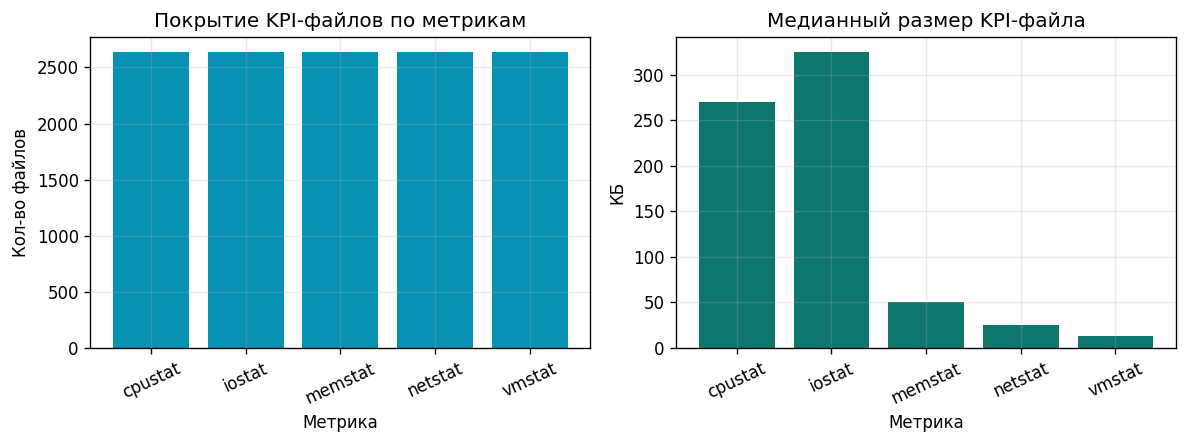

In [7]:
kpi_rows = []
for _, row in strict.iterrows():
    instruments = RAW_DATA / row["workload"] / "kpis" / row["scenario"] / "instruments"
    if not instruments.exists():
        continue
    for host_dir in sorted([p for p in instruments.iterdir() if p.is_dir() and not p.name.startswith(".")]):
        for metric in KPI_SELECTED_COLUMNS:
            path = host_dir / metric
            if path.exists():
                kpi_rows.append(
                    {
                        "run_id": row["run_id"],
                        "workload": row["workload"],
                        "scenario_type": row["scenario_type"],
                        "host": host_dir.name,
                        "metric": metric,
                        "size_kb": path.stat().st_size / 1024.0,
                    }
                )
kpi_meta = pd.DataFrame(kpi_rows)
metric_summary = (
    kpi_meta.groupby("metric")
    .agg(файлы=("metric", "size"), запуски=("run_id", "nunique"), хосты=("host", "nunique"), медиана_размера_кб=("size_kb", "median"))
    .reset_index()
    .sort_values("файлы", ascending=False)
)
display(metric_summary)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].bar(metric_summary["metric"], metric_summary["файлы"], color="#0891b2")
axes[0].set_title("Покрытие KPI-файлов по метрикам")
axes[0].set_ylabel("Кол-во файлов")
axes[0].set_xlabel("Метрика")
axes[0].tick_params(axis="x", rotation=25)

axes[1].bar(metric_summary["metric"], metric_summary["медиана_размера_кб"], color="#0f766e")
axes[1].set_title("Медианный размер KPI-файла")
axes[1].set_ylabel("КБ")
axes[1].set_xlabel("Метрика")
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()


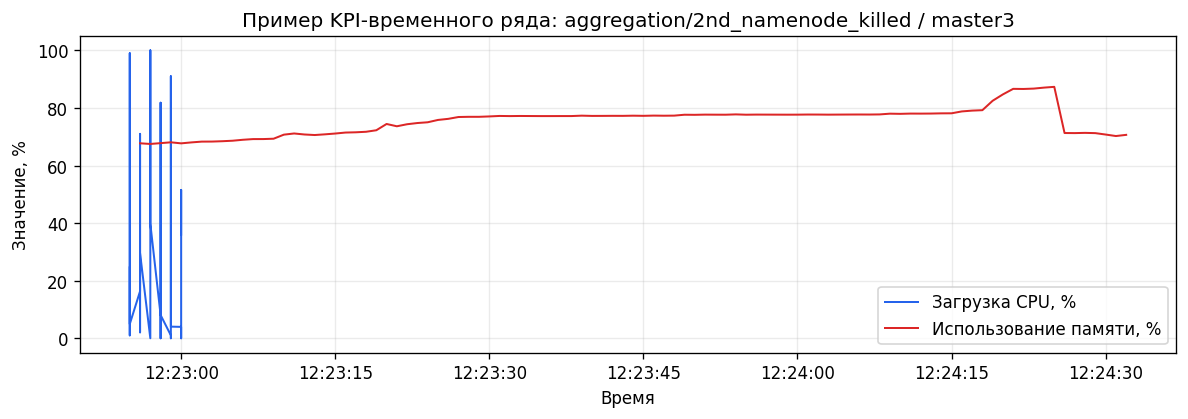

In [8]:
sample_run = strict.loc[strict["scenario_type"].eq("failure")].iloc[0]
sample_dir = RAW_DATA / sample_run["workload"] / "kpis" / sample_run["scenario"] / "instruments"
host_dir = next(p for p in sample_dir.iterdir() if p.is_dir())
cpu = _read_kpi_file(host_dir / "cpustat", "cpustat")
mem = _read_kpi_file(host_dir / "memstat", "memstat")

fig, ax = plt.subplots(figsize=(10, 3.6))
if not cpu.empty and "%idle" in cpu.columns:
    cpu_plot = cpu.sort_values("timestamp").head(220)
    ax.plot(cpu_plot["timestamp"], 100.0 - cpu_plot["%idle"], label="Загрузка CPU, %", color="#2563eb", linewidth=1.2)
if not mem.empty and "%memused" in mem.columns:
    mem_plot = mem.sort_values("timestamp").head(220)
    ax.plot(mem_plot["timestamp"], mem_plot["%memused"], label="Использование памяти, %", color="#dc2626", linewidth=1.2)
ax.set_title(f"Пример KPI-временного ряда: {sample_run['run_id']} / {host_dir.name}")
ax.set_ylabel("Значение, %")
ax.set_xlabel("Время")
ax.legend()
plt.tight_layout()
plt.show()


**Что показано.** Покрытие KPI-файлов и пример физического временного ряда.  
**Что наблюдается.** KPI имеют высокое временное разрешение и хорошо подходят для оконной агрегации, но сами по себе не всегда различают нормальную нагрузку и предаварийную деградацию.  
**Локальный вывод.** Финальная модель должна не заменять логи на KPI, а объединять оба источника через единый fusion-блок и маски доступности.


## 6. Методические риски и решения

На основе EDA фиксируются решения для следующего этапа:

1. **Единица наблюдения** — временное окно внутри `run_id`, а не строка лога.
2. **Источник таргета** — explicit failure anchor из raw log, без использования целевой метки как score.
3. **Защита от поздней утечки** — `gap10`: окно слишком близко к событию исключается.
4. **Мультимодальность** — logs и KPI сохраняются вместе с масками доступности, а не сливаются в неинтерпретируемый набор чисел.
5. **Оценка качества** — baseline и модель сравниваются на workload/run-aware split.


In [9]:
eda_payload = {
    "raw_data": str(RAW_DATA.relative_to(PROJECT_ROOT)),
    "strict_runs": int(strict["run_id"].nunique()),
    "workloads": int(strict["workload"].nunique()),
    "normal_runs": int(strict.loc[strict["scenario_type"].eq("normal"), "run_id"].nunique()),
    "failure_runs": int(strict.loc[strict["scenario_type"].eq("failure"), "run_id"].nunique()),
    "log_stats": {
        "parsed_runs": int(log_stats["run_id"].nunique()),
        "median_duration_sec": float(log_stats["duration_sec"].median()),
        "median_log_events": float(log_stats["event_count"].median()),
        "explicit_anchor_failure_share": float(log_stats.loc[log_stats["scenario_type"].eq("failure"), "explicit_anchor_available"].mean()),
    },
    "kpi_stats": {
        "files": int(len(kpi_meta)),
        "metrics": sorted(kpi_meta["metric"].unique().tolist()),
        "hosts": int(kpi_meta["host"].nunique()),
    },
}
write_json(REPORT_DIR / "01_eda_summary.json", eda_payload)
print("Записано:", (REPORT_DIR / "01_eda_summary.json").relative_to(PROJECT_ROOT))


Записано: dashboard\artifacts\reports\01_eda_summary.json


**Итоговый вывод.** Данные пригодны для лабораторного AIOps replay-прототипа, но требуют строгого протокола. Главная сложность не в отсутствии признаков, а в корректном времени наблюдения: модель должна использовать только то, что было видно до события. Следующий ноутбук формирует такой contract и проверяет базовые модели.
